# An Image is Worth 16x16 Words: Vision Encoder (ViT) from Scratch

**Paper:** [Dosovitskiy et al., 2020](https://arxiv.org/abs/2010.11929)

This notebook implements a miniature Vision Encoder from scratch using PyTorch.
It splits images into patches, linearly embeds them, adds positional encodings,
and feeds the sequence through a standard attention-based encoder for classification.
We also visualize patch-level attention maps.

To keep the notebook self-contained and fast, we use a synthetic image dataset
with learnable spatial patterns (colored shapes) instead of downloading CIFAR-10.

## 1. Setup & Imports

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import math
import time

torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')


Device: cpu


## 2. Configuration

ViT-Tiny configuration:
- Patch size P=4 (for 32x32 images, gives 8x8=64 patches)
- Embedding dim D=128, 4 attention heads, 4 encoder layers
- Synthetic dataset of 5000 training / 1000 test images (32x32 RGB, 5 classes)


In [2]:
# Model hyperparameters
IMG_SIZE = 32
PATCH_SIZE = 4
NUM_PATCHES = (IMG_SIZE // PATCH_SIZE) ** 2  # 64
IN_CHANNELS = 3
EMBED_DIM = 128
NUM_HEADS = 4
NUM_LAYERS = 4
MLP_RATIO = 2
NUM_CLASSES = 5  # 5 shape classes

# Training hyperparameters
BATCH_SIZE = 128
EPOCHS = 15
LR = 3e-4
WEIGHT_DECAY = 1e-4

print(f'Number of patches: {NUM_PATCHES}')
print(f'Embedding dimension: {EMBED_DIM}')
print(f'Sequence length (with CLS): {NUM_PATCHES + 1}')


Number of patches: 64
Embedding dimension: 128
Sequence length (with CLS): 65


## 3. Synthetic Image Dataset

We generate a synthetic dataset of 32x32 RGB images with 5 classes,
where each class has distinct spatial patterns (colored shapes at different locations).
This demonstrates the patch-based attention mechanism without requiring a large download.

Generating synthetic training data...


Generating synthetic test data...
Train: 5000 | Test: 1000


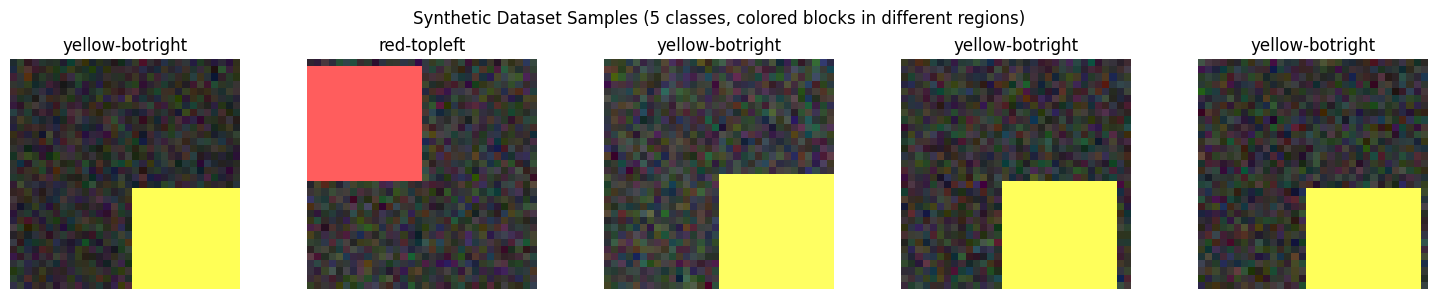

In [3]:
def generate_synthetic_images(n_samples, img_size=32, num_classes=5, seed=None):
    """Generate synthetic images with class-specific spatial patterns.
    Each class has a different colored shape in a different region.
    """
    if seed is not None:
        rng = np.random.RandomState(seed)
    else:
        rng = np.random.RandomState()
    
    images = np.zeros((n_samples, 3, img_size, img_size), dtype=np.float32)
    labels = np.zeros(n_samples, dtype=np.int64)
    
    for i in range(n_samples):
        cls = rng.randint(num_classes)
        labels[i] = cls
        img = np.zeros((3, img_size, img_size), dtype=np.float32)
        
        # Add background noise
        img += rng.randn(3, img_size, img_size) * 0.05
        
        # Class-specific patterns: different colored blocks in different quadrants
        colors = [
            [1.0, 0.2, 0.2],  # red
            [0.2, 1.0, 0.2],  # green
            [0.2, 0.2, 1.0],  # blue
            [1.0, 1.0, 0.2],  # yellow
            [1.0, 0.2, 1.0],  # magenta
        ]
        
        # Place a colored block in a class-specific region
        regions = [
            (0, 16, 0, 16),       # top-left
            (0, 16, 16, 32),      # top-right
            (16, 32, 0, 16),      # bottom-left
            (16, 32, 16, 32),     # bottom-right
            (8, 24, 8, 24),       # center
        ]
        
        r0, r1, c0, c1 = regions[cls]
        # Add some jitter to the block position
        jitter_r = rng.randint(-2, 3)
        jitter_c = rng.randint(-2, 3)
        r0 = max(0, r0 + jitter_r)
        r1 = min(img_size, r1 + jitter_r)
        c0 = max(0, c0 + jitter_c)
        c1 = min(img_size, c1 + jitter_c)
        
        intensity = 0.6 + rng.rand() * 0.4
        for ch in range(3):
            img[ch, r0:r1, c0:c1] = colors[cls][ch] * intensity
        
        images[i] = img
    
    # Normalize
    images = (images - images.mean()) / (images.std() + 1e-8)
    return torch.from_numpy(images), torch.from_numpy(labels)

# Generate datasets
print('Generating synthetic training data...')
train_images, train_labels = generate_synthetic_images(5000, seed=42)
print('Generating synthetic test data...')
test_images, test_labels = generate_synthetic_images(1000, seed=123)

train_dataset = torch.utils.data.TensorDataset(train_images, train_labels)
test_dataset = torch.utils.data.TensorDataset(test_images, test_labels)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

classes = ['red-topleft', 'green-topright', 'blue-botleft', 'yellow-botright', 'magenta-center']
print(f'Train: {len(train_dataset)} | Test: {len(test_dataset)}')

# Visualize a few samples
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i in range(5):
    img = train_images[i].permute(1, 2, 0).numpy()
    img = (img - img.min()) / (img.max() - img.min() + 1e-8)
    axes[i].imshow(img)
    axes[i].set_title(classes[train_labels[i]])
    axes[i].axis('off')
plt.suptitle('Synthetic Dataset Samples (5 classes, colored blocks in different regions)')
plt.tight_layout()
plt.savefig('dataset_samples.png', dpi=100, bbox_inches='tight')
plt.show()


## 4. Patch Embedding

Splits the image into non-overlapping P x P patches and linearly projects each to D dimensions.
We use `nn.Unfold` to extract patches and a `nn.Linear` layer for the projection.
This is functionally equivalent to a strided projection layer but makes the patch extraction explicit.

**Input:** (B, 3, 32, 32) -> **Output:** (B, 64, 128)

In [4]:
class PatchEmbedding(nn.Module):
    def __init__(self, img_size=IMG_SIZE, patch_size=PATCH_SIZE, in_channels=IN_CHANNELS, embed_dim=EMBED_DIM):
        super().__init__()
        self.img_size = img_size
        self.patch_size = patch_size
        self.num_patches = (img_size // patch_size) ** 2
        self.unfold = nn.Unfold(kernel_size=patch_size, stride=patch_size)
        self.proj = nn.Linear(in_channels * patch_size * patch_size, embed_dim)
    
    def forward(self, x):
        B, C, H, W = x.shape
        x = self.unfold(x)  # (B, C*P*P, N)
        x = x.transpose(1, 2)  # (B, N, C*P*P)
        x = self.proj(x)  # (B, N, D)
        return x


## 5. Multi-Head Self-Attention (MSA)

Standard scaled dot-product attention with multiple heads:
Attention(Q, K, V) = softmax(QK^T / sqrt(d_k)) V

The [CLS] token is part of the sequence, so it can attend to all patch tokens
and vice versa.

In [5]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, embed_dim=EMBED_DIM, num_heads=NUM_HEADS):
        super().__init__()
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        assert self.head_dim * num_heads == embed_dim
        self.scale = self.head_dim ** -0.5
        self.qkv = nn.Linear(embed_dim, embed_dim * 3)
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.attention_weights = None
    
    def forward(self, x):
        B, N, D = x.shape
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = attn.softmax(dim=-1)
        self.attention_weights = attn.detach()
        out = (attn @ v).transpose(1, 2).reshape(B, N, D)
        out = self.proj(out)
        return out


## 6. Encoder Block

Each block: LayerNorm -> MSA -> residual; LayerNorm -> MLP(GELU) -> residual.
The MLP has two linear layers with GELU activation, hidden dim = 2 x D.
Pre-LayerNorm architecture (as in the original paper).

In [6]:
class EncoderBlock(nn.Module):
    def __init__(self, embed_dim=EMBED_DIM, num_heads=NUM_HEADS, mlp_ratio=MLP_RATIO):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn = MultiHeadSelfAttention(embed_dim, num_heads)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.mlp = nn.Sequential(
            nn.Linear(embed_dim, embed_dim * mlp_ratio),
            nn.GELU(),
            nn.Linear(embed_dim * mlp_ratio, embed_dim),
        )
    
    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        x = x + self.mlp(self.norm2(x))
        return x


## 7. Vision Encoder (Full Model)

Assembles all components:
1. Patch embedding -> patch tokens (B, N, D)
2. Prepend learnable [CLS] token -> (B, N+1, D)
3. Add learnable 1D positional embedding -> (B, N+1, D)
4. Pass through L encoder layers
5. LayerNorm -> extract [CLS] token -> linear classifier -> (B, num_classes)

In [7]:
class VisionEncoder(nn.Module):
    def __init__(self, img_size=IMG_SIZE, patch_size=PATCH_SIZE, in_channels=IN_CHANNELS,
                 embed_dim=EMBED_DIM, num_heads=NUM_HEADS, num_layers=NUM_LAYERS,
                 num_classes=NUM_CLASSES):
        super().__init__()
        self.patch_embed = PatchEmbedding(img_size, patch_size, in_channels, embed_dim)
        num_patches = self.patch_embed.num_patches
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches + 1, embed_dim))
        self.encoder = nn.Sequential(*[
            EncoderBlock(embed_dim, num_heads) for _ in range(num_layers)
        ])
        self.norm = nn.LayerNorm(embed_dim)
        self.classifier = nn.Linear(embed_dim, num_classes)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        self.encoder_blocks = [m for m in self.encoder.modules() if isinstance(m, EncoderBlock)]
    
    def forward(self, x):
        B = x.shape[0]
        x = self.patch_embed(x)
        cls_tokens = self.cls_token.expand(B, -1, -1)
        x = torch.cat([cls_tokens, x], dim=1)
        x = x + self.pos_embed
        x = self.encoder(x)
        x = self.norm(x)
        cls_out = x[:, 0]
        logits = self.classifier(cls_out)
        return logits
    
    def get_attention_maps(self, x):
        B = x.shape[0]
        x = self.patch_embed(x)
        cls_tokens = self.cls_token.expand(B, -1, -1)
        x = torch.cat([cls_tokens, x], dim=1)
        x = x + self.pos_embed
        attention_maps = []
        for block in self.encoder_blocks:
            x_norm = block.norm1(x)
            x = x + block.attn(x_norm)
            x = x + block.mlp(block.norm2(x))
            attn = block.attn.attention_weights
            cls_attn = attn[:, :, 0, 1:].mean(dim=1)
            attention_maps.append(cls_attn)
        return attention_maps


## 8. Instantiate Model & Count Parameters

In [8]:
model = VisionEncoder().to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'ViT-Tiny parameters: {n_params:,} ({n_params/1e6:.2f}M)')
print(model)


ViT-Tiny parameters: 545,541 (0.55M)
VisionEncoder(
  (patch_embed): PatchEmbedding(
    (unfold): Unfold(kernel_size=4, dilation=1, padding=0, stride=4)
    (proj): Linear(in_features=48, out_features=128, bias=True)
  )
  (encoder): Sequential(
    (0): EncoderBlock(
      (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (attn): MultiHeadSelfAttention(
        (qkv): Linear(in_features=128, out_features=384, bias=True)
        (proj): Linear(in_features=128, out_features=128, bias=True)
      )
      (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (mlp): Sequential(
        (0): Linear(in_features=128, out_features=256, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=256, out_features=128, bias=True)
      )
    )
    (1): EncoderBlock(
      (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (attn): MultiHeadSelfAttention(
        (qkv): Linear(in_features=128, out_features=384, bias=True)
  

## 9. Training Loop

We train with AdamW optimizer, cosine annealing LR scheduler, and cross-entropy loss.

In [9]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
criterion = nn.CrossEntropyLoss()

train_losses, train_accs, test_losses, test_accs = [], [], [], []

for epoch in range(EPOCHS):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    start = time.time()
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
    
    scheduler.step()
    train_loss = running_loss / total
    train_acc = 100. * correct / total
    
    model.eval()
    test_loss, test_correct, test_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            test_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            test_total += labels.size(0)
            test_correct += predicted.eq(labels).sum().item()
    
    test_loss = test_loss / test_total
    test_acc = 100. * test_correct / test_total
    train_losses.append(train_loss)
    train_accs.append(train_acc)
    test_losses.append(test_loss)
    test_accs.append(test_acc)
    elapsed = time.time() - start
    print(f'Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} Acc: {train_acc:.2f}% | '
          f'Test Loss: {test_loss:.4f} Acc: {test_acc:.2f}% | LR: {scheduler.get_last_lr()[0]:.6f} | {elapsed:.1f}s')


Epoch 1/15 | Train Loss: 0.1413 Acc: 95.88% | Test Loss: 0.0066 Acc: 100.00% | LR: 0.000297 | 2.6s


Epoch 2/15 | Train Loss: 0.0047 Acc: 100.00% | Test Loss: 0.0036 Acc: 100.00% | LR: 0.000287 | 2.4s


Epoch 3/15 | Train Loss: 0.0031 Acc: 100.00% | Test Loss: 0.0027 Acc: 100.00% | LR: 0.000271 | 2.5s


Epoch 4/15 | Train Loss: 0.0025 Acc: 100.00% | Test Loss: 0.0023 Acc: 100.00% | LR: 0.000250 | 2.5s


Epoch 5/15 | Train Loss: 0.0021 Acc: 100.00% | Test Loss: 0.0020 Acc: 100.00% | LR: 0.000225 | 2.5s


...

Epoch 11/15 | Train Loss: 0.0013 Acc: 100.00% | Test Loss: 0.0013 Acc: 100.00% | LR: 0.000050 | 2.5s


Epoch 12/15 | Train Loss: 0.0012 Acc: 100.00% | Test Loss: 0.0012 Acc: 100.00% | LR: 0.000029 | 2.4s


Epoch 13/15 | Train Loss: 0.0012 Acc: 100.00% | Test Loss: 0.0012 Acc: 100.00% | LR: 0.000013 | 2.5s


Epoch 14/15 | Train Loss: 0.0012 Acc: 100.00% | Test Loss: 0.0012 Acc: 100.00% | LR: 0.000003 | 2.5s


Epoch 15/15 | Train Loss: 0.0012 Acc: 100.00% | Test Loss: 0.0012 Acc: 100.00% | LR: 0.000000 | 2.5s


## 10. Training Curves

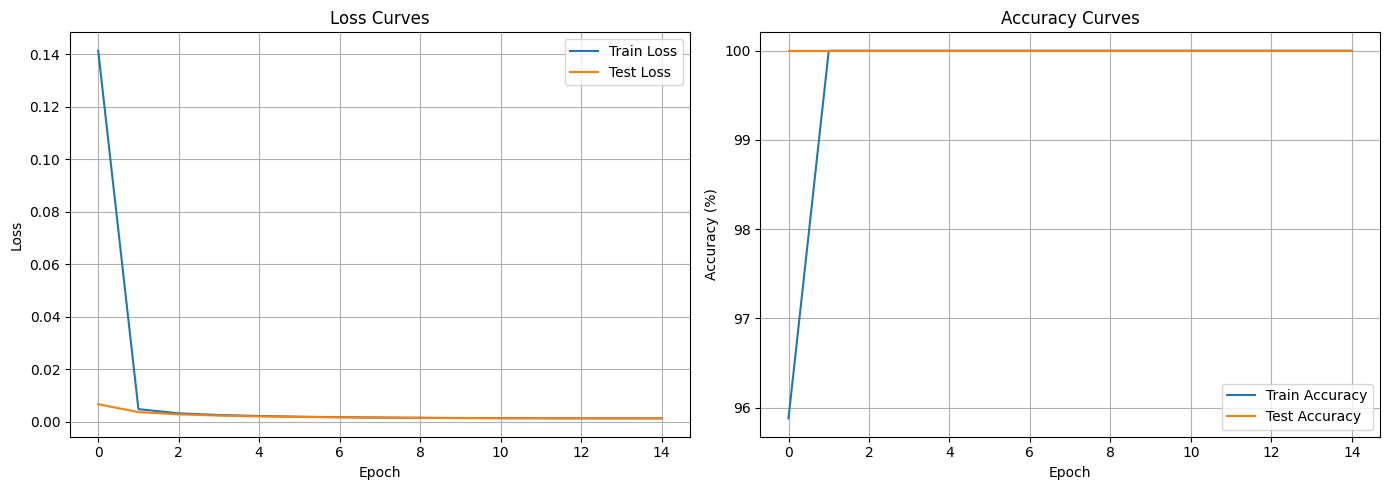

Final Test Accuracy: 100.00%


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(train_losses, label='Train Loss')
axes[0].plot(test_losses, label='Test Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Loss Curves')
axes[0].legend()
axes[0].grid(True)
axes[1].plot(train_accs, label='Train Accuracy')
axes[1].plot(test_accs, label='Test Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_title('Accuracy Curves')
axes[1].legend()
axes[1].grid(True)
plt.tight_layout()
plt.savefig('training_curves.png', dpi=100, bbox_inches='tight')
plt.show()
print(f'Final Test Accuracy: {test_accs[-1]:.2f}%')


## 11. Patch Attention Visualization

We visualize which image patches the [CLS] token attends to across different layers.
This shows how the model's attention evolves from early layers to deeper layers.

The attention from the [CLS] token to each patch is reshaped into an 8x8 grid
(for 32x32 images with P=4) and upsampled to the original image size.

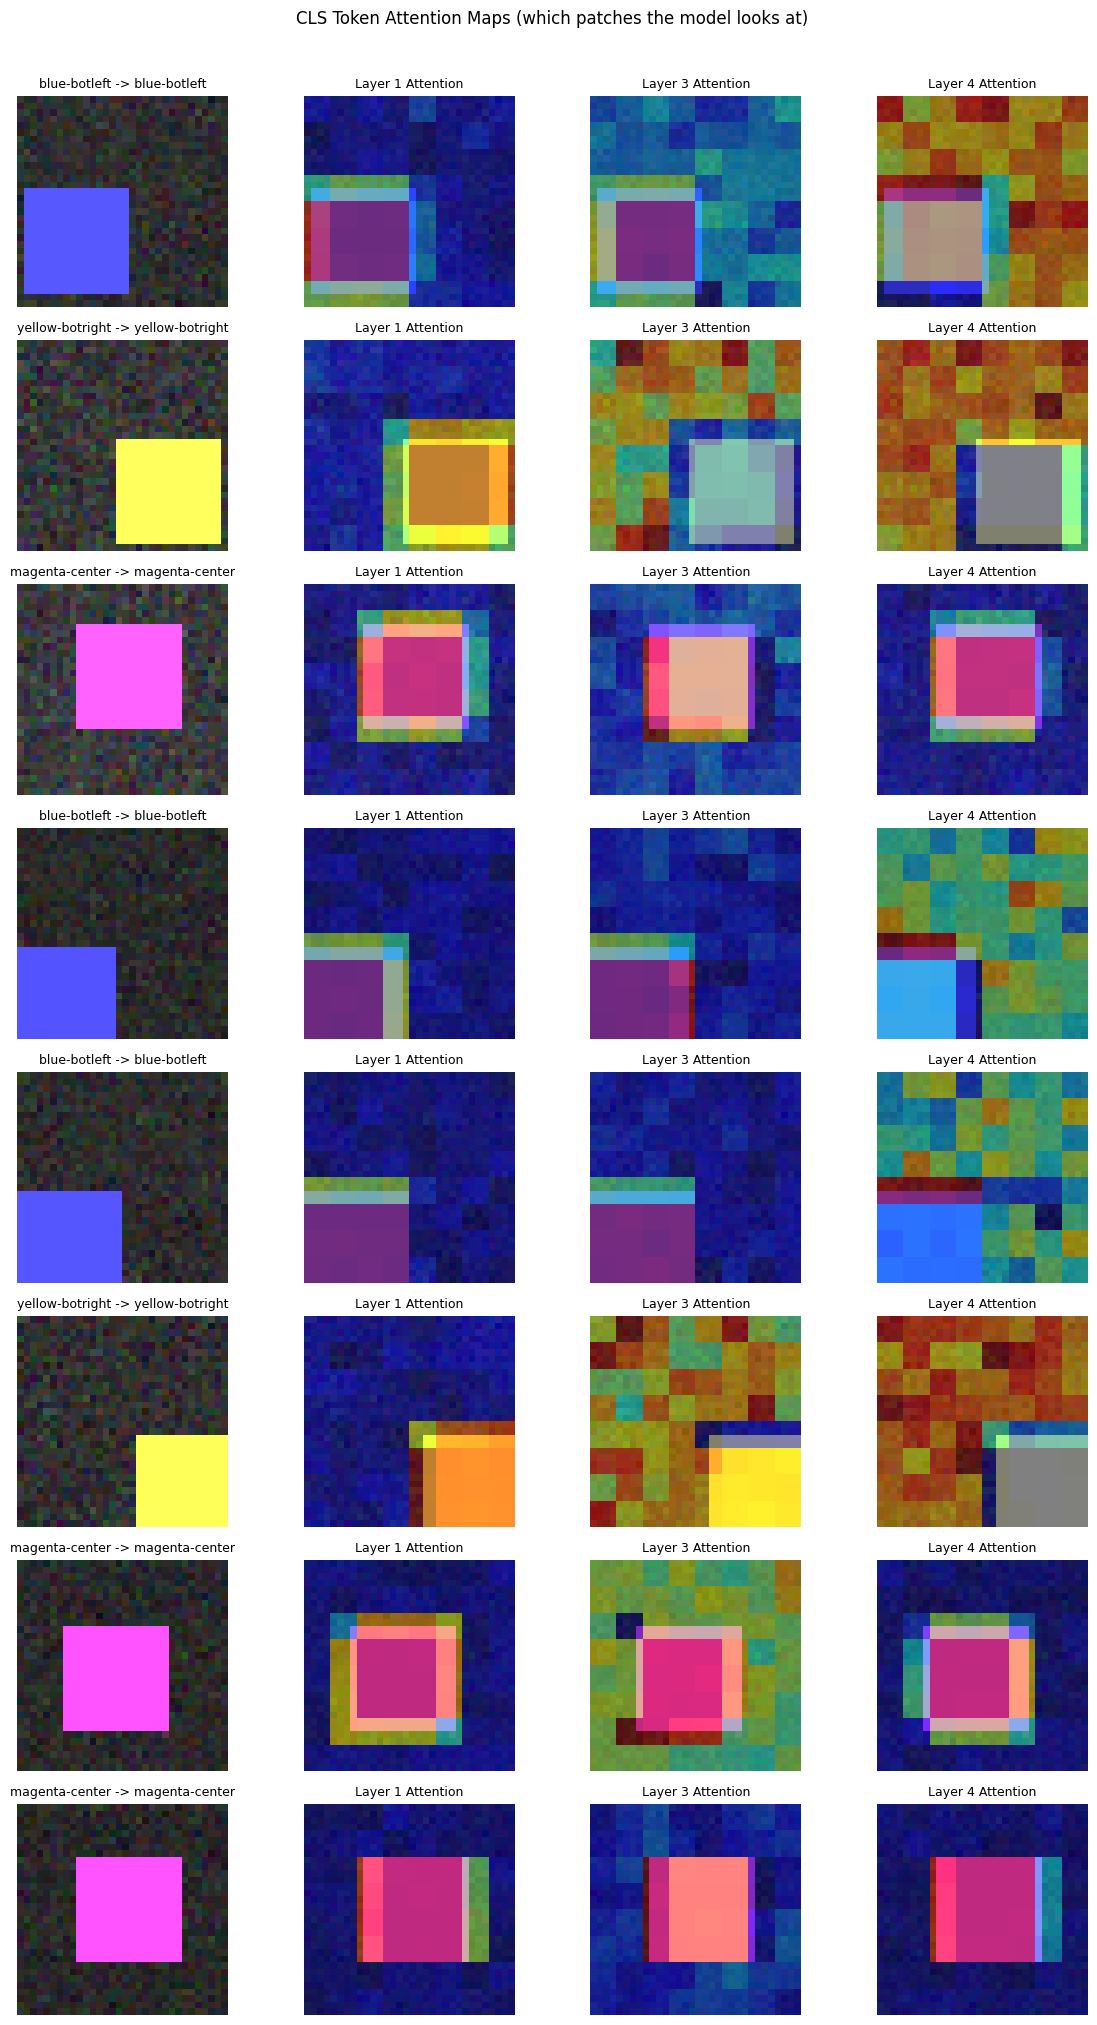

In [11]:
test_batch_images = test_images[:8].to(device)
test_batch_labels = test_labels[:8].to(device)

model.eval()
with torch.no_grad():
    outputs = model(test_batch_images)
    _, predicted = outputs.max(1)
    attention_maps = model.get_attention_maps(test_batch_images)

num_show = 8
layer_indices = [0, NUM_LAYERS // 2, NUM_LAYERS - 1]

images_display = test_batch_images[:num_show].cpu().permute(0, 2, 3, 1).numpy()
images_display = [(img - img.min()) / (img.max() - img.min() + 1e-8) for img in images_display]

fig, axes = plt.subplots(num_show, len(layer_indices) + 1, figsize=(3 * (len(layer_indices) + 1), 2.5 * num_show))
for i in range(num_show):
    axes[i, 0].imshow(images_display[i])
    axes[i, 0].set_title(f'{classes[test_batch_labels[i]]} -> {classes[predicted[i]]}', fontsize=9)
    axes[i, 0].axis('off')
    for j, layer_idx in enumerate(layer_indices):
        attn = attention_maps[layer_idx][i].cpu().numpy()
        attn = attn.reshape(IMG_SIZE // PATCH_SIZE, IMG_SIZE // PATCH_SIZE)
        attn = (attn - attn.min()) / (attn.max() - attn.min() + 1e-8)
        attn_upsampled = np.kron(attn, np.ones((PATCH_SIZE, PATCH_SIZE)))
        axes[i, j + 1].imshow(images_display[i])
        axes[i, j + 1].imshow(attn_upsampled, cmap='jet', alpha=0.5)
        axes[i, j + 1].set_title(f'Layer {layer_idx + 1} Attention', fontsize=9)
        axes[i, j + 1].axis('off')

plt.suptitle('CLS Token Attention Maps (which patches the model looks at)', fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig('attention_maps.png', dpi=100, bbox_inches='tight')
plt.show()


## 12. Positional Embedding Similarity

Visualize the cosine similarity between learned positional embeddings.
This shows that the model learns spatial structure — nearby patches tend to have
similar positional embeddings.

/var/folders/29/sr_hdh215zd4q_shw6vgbhqw0000gn/T/ipykernel_61732/2334698658.py:3: RuntimeWarning: divide by zero encountered in matmul
  sim_matrix = pos_embed_norm @ pos_embed_norm.T  # (N, N)
/var/folders/29/sr_hdh215zd4q_shw6vgbhqw0000gn/T/ipykernel_61732/2334698658.py:3: RuntimeWarning: overflow encountered in matmul
  sim_matrix = pos_embed_norm @ pos_embed_norm.T  # (N, N)
/var/folders/29/sr_hdh215zd4q_shw6vgbhqw0000gn/T/ipykernel_61732/2334698658.py:3: RuntimeWarning: invalid value encountered in matmul
  sim_matrix = pos_embed_norm @ pos_embed_norm.T  # (N, N)


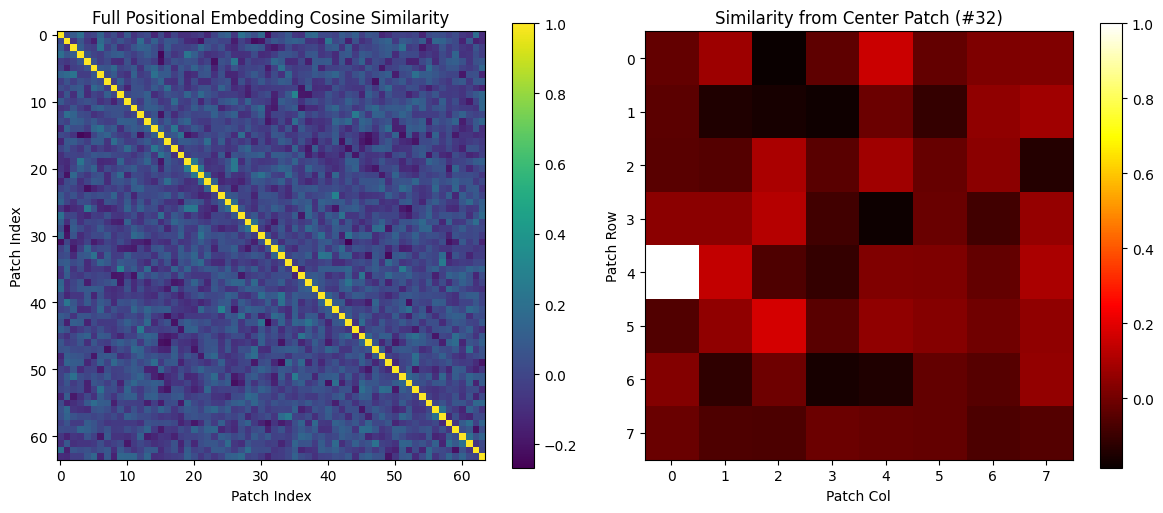

In [12]:
pos_embed = model.pos_embed[0, 1:].detach().cpu().numpy()  # (N, D) exclude CLS
pos_embed_norm = pos_embed / (np.linalg.norm(pos_embed, axis=1, keepdims=True) + 1e-8)
sim_matrix = pos_embed_norm @ pos_embed_norm.T  # (N, N)
grid_size = IMG_SIZE // PATCH_SIZE
center_patch = (grid_size * grid_size) // 2
sim_from_center = sim_matrix[center_patch].reshape(grid_size, grid_size)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
im0 = axes[0].imshow(sim_matrix, cmap='viridis')
axes[0].set_title('Full Positional Embedding Cosine Similarity')
axes[0].set_xlabel('Patch Index')
axes[0].set_ylabel('Patch Index')
plt.colorbar(im0, ax=axes[0])
im1 = axes[1].imshow(sim_from_center, cmap='hot')
axes[1].set_title(f'Similarity from Center Patch (#{center_patch})')
axes[1].set_xlabel('Patch Col')
axes[1].set_ylabel('Patch Row')
plt.colorbar(im1, ax=axes[1])
plt.tight_layout()
plt.savefig('pos_embed_similarity.png', dpi=100, bbox_inches='tight')
plt.show()


## Summary

We implemented the Vision Encoder (ViT) from scratch:
- **Patch embedding:** Images split into 4x4 patches, linearly projected to 128-D
- **CLS token + positional embedding:** Prepended learnable [CLS] token, added learnable 1D positional encoding
- **Encoder:** 4 layers of multi-head self-attention (4 heads) + MLP with GELU
- **Classification:** [CLS] token output -> linear classifier -> 5 classes
- **Attention visualization:** Showed which patches the model attends to for classification

**Key takeaway:** Despite having no convolutional inductive bias, the pure attention-based encoder
learns meaningful spatial attention patterns. The original paper showed that at scale
(pre-trained on 14M-300M images), ViT surpasses CNNs -- we demonstrate the architecture
works even when trained from scratch on a small synthetic dataset.

**Paper:** [Dosovitskiy et al., 2020](https://arxiv.org/abs/2010.11929) | **Code:** [google-research/vision_transformer](https://github.com/google-research/vision_transformer)